# 07_Final_Synthesis — Synthèse finale

**Projet :** Credit Risk Scorecard · **Phase 5** — restitution · Données : Home Credit Default Risk (Kaggle).

- Vue d'ensemble en une page : chiffres clés, quatre figures, recommandation.
- Ce notebook **relit les sorties** des Phases 3 et 4 (`output/tables/`) ; il ne réentraîne rien et n'ouvre pas le test dans la base.
- Documents associés : `docs/note_comite_credit.md`, `docs/model_card.md` (générés par `scripts/build_reports.py`), `docs/powerbi_guide.md`.
- Figures écrites : `output/07_*.png`.

In [1]:
# --- Setup : vérification du répertoire de travail, connexion DuckDB en lecture seule ---
import os
import sys
from pathlib import Path

cwd = Path.cwd()
# Jupyter / VS Code lancent le noyau dans notebooks/ : on remonte d'un niveau si c'est le cas.
if cwd.name == "notebooks" and (cwd.parent / "scripts" / "config.py").is_file():
    os.chdir(cwd.parent)
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name != "credit-risk-scorecard" or not (PROJECT_ROOT / "scripts" / "config.py").is_file():
    raise RuntimeError(
        f"Répertoire de travail inattendu : {PROJECT_ROOT}. "
        "Lancer le notebook depuis la racine credit-risk-scorecard/ (ou depuis notebooks/)."
    )
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

import hashlib

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from config import DB_PATH, FIGURES_DIR

if not DB_PATH.exists():
    raise FileNotFoundError(f"{DB_PATH} introuvable.")
con = duckdb.connect(str(DB_PATH), read_only=True)

# Style des figures : identique aux notebooks 00 à 05
BLUE, INK, INK2, GRID, GREY = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#a3a29d"
RED = "#c8553d"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11, "font.size": 9,
})
print("Racine :", PROJECT_ROOT.name)
print(f"Python {sys.version.split()[0]} · duckdb {duckdb.__version__} · pandas {pd.__version__} · matplotlib {matplotlib.__version__}")

Racine : credit-risk-scorecard
Python 3.13.15 · duckdb 1.5.5 · pandas 3.0.6 · matplotlib 3.11.2


In [2]:
# --- Sorties des Phases 3 et 4 ---
import json

import build_reports as br
from config import TABLES_DIR

d = br.load_inputs()          # lève une erreur si les sorties sont des répétitions (--dry-run)
k = br.key_numbers(d)
ev, st = d["ev"], d["st"]
scen = d["scen"]
reco = st["recommended"]
LGD = st["lgd_base"]
deciles = pd.read_csv(TABLES_DIR / "score_deciles.csv")
o = ev["test_opening"]
print(f"Dernière lecture du test : {o['timestamp_utc']} · {o['n_rows']:,} demandes · empreinte conforme : {o['fingerprint_match']}")
print(f"Scénario recommandé : {br.SCENARIO_LABELS[reco]} (seuil {st['cutoffs'][reco]['cutoff']}), LGD de base {LGD:.0%}")

Dernière lecture du test : 2026-10-08T09:48:02Z · 46,127 demandes · empreinte conforme : True
Scénario recommandé : Prudent (seuil 563), LGD de base 45%


## 1. Chiffres clés (test)

Grille : AUC et KS sur le score entier, Brier sur la PD du logit. IC à 95 % : bootstrap apparié (1 000 rééchantillonnages).

In [3]:
b = k["boot"]
models = pd.DataFrame([
    {"modèle": "Grille de score", "AUC": k["auc"][("scorecard", "test")], "IC bas": b["scorecard_auc"]["low"],
     "IC haut": b["scorecard_auc"]["high"], "Gini": k["gini"][("scorecard", "test")], "KS": k["ks"][("scorecard", "test")],
     "Brier": k["brier"][("scorecard", "test")], "AUC train": k["auc"][("scorecard", "train")]},
    {"modèle": "LightGBM (challenger)", "AUC": k["auc"][("lgbm", "test")], "IC bas": b["lgbm_auc"]["low"],
     "IC haut": b["lgbm_auc"]["high"], "Gini": k["gini"][("lgbm", "test")], "KS": k["ks"][("lgbm", "test")],
     "Brier": k["brier"][("lgbm", "test")], "AUC train": k["auc"][("lgbm", "train")]},
])
display(models.style.format({c: "{:.4f}" for c in models.columns[1:]}).hide(axis="index"))

rt, al = k["rt"], k["all"]
kpi = pd.DataFrame([
    ("Taux de défaut sans seuil", f"{al['bad_rate_accepted']:.2%}"),
    ("Seuil recommandé", f"{rt['cutoff']} (revue {rt['review_low']}–{rt['review_high'] - 1})"),
    ("Taux d'acceptation", f"{rt['approval_rate']:.1%}"),
    ("Défaut des acceptés", f"{rt['bad_rate_accepted']:.2%}"),
    ("Perte attendue évitée", f"{rt['el_avoided'] / 1e6:,.1f} M ({rt['el_avoided_pct']:.1%})"),
    ("Bons clients refusés", f"{rt['good_refused_pct']:.1%}"),
    ("Zone de revue", f"{rt['zone_review_pct']:.1%}"),
    ("Écart d'AUC LightGBM − grille", f"{b['auc_diff_lgbm_minus_scorecard']['estimate']:.4f} "
                                      f"[{b['auc_diff_lgbm_minus_scorecard']['low']:.4f} ; {b['auc_diff_lgbm_minus_scorecard']['high']:.4f}]"),
    ("PSI du score train → test", f"{k['psi']['score_train_test']:.4f}"),
    ("Ratio d'acceptation H/F", f"{k['ratio_mf']:.3f} (bons clients : {k['ratio_mf_goods']:.3f})"),
], columns=["indicateur", "valeur (test)"])
display(kpi.style.hide(axis="index"))

modèle,AUC,IC bas,IC haut,Gini,KS,Brier,AUC train
Grille de score,0.7518,0.7437,0.7598,0.5035,0.3762,0.0684,0.7544
LightGBM (challenger),0.7883,0.7809,0.7960,0.5766,0.4384,0.0659,0.8808


indicateur,valeur (test)
Taux de défaut sans seuil,8.07%
Seuil recommandé,563 (revue 553–572)
Taux d'acceptation,60.3%
Défaut des acceptés,3.44%
Perte attendue évitée,632.6 M (69.9%)
Bons clients refusés,36.7%
Zone de revue,25.4%
Écart d'AUC LightGBM − grille,0.0365 [0.0319 ; 0.0408]
PSI du score train → test,0.0001
Ratio d'acceptation H/F,0.821 (bons clients : 0.841)


## 2. Figures clés

### 2.1 Discrimination : la grille est stable, LightGBM plus performant mais sur-appris

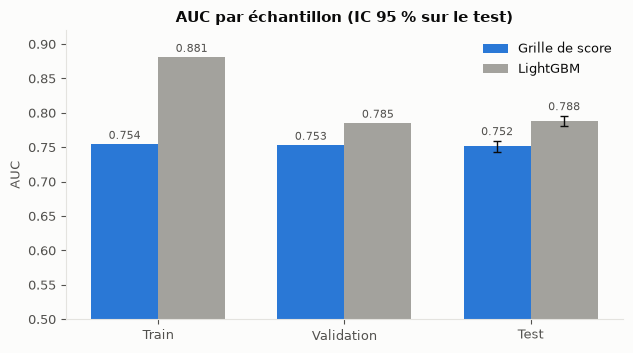

In [4]:
SPL = {"train": "Train", "valid": "Validation", "test": "Test"}
fig, ax = plt.subplots(figsize=(6.4, 3.6))
x = np.arange(3)
w = 0.36
for i, (m, col, lab) in enumerate((("scorecard", BLUE, "Grille de score"), ("lgbm", GREY, "LightGBM"))):
    vals = [k["auc"][(m, s)] for s in SPL]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, color=col, label=lab)
    key = "scorecard_auc" if m == "scorecard" else "lgbm_auc"
    ax.errorbar(x[2] + (i - 0.5) * w, vals[2], yerr=[[vals[2] - b[key]["low"]], [b[key]["high"] - vals[2]]],
                color=INK, capsize=3, lw=1)
    tops = [vals[0], vals[1], b[key]["high"]]           # sur le test : étiquette au-dessus de l'IC
    for xi, v, t in zip(x + (i - 0.5) * w, vals, tops):
        ax.text(xi, t + 0.004, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color=INK2)
ax.set_xticks(x, list(SPL.values()))
ax.set_ylim(0.5, 0.92)
ax.set_ylabel("AUC")
ax.set_title("AUC par échantillon (IC 95 % sur le test)")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_auc_models.png", dpi=150)
plt.show()

### 2.2 Le score classe le risque : taux de défaut par tranche de score (test)

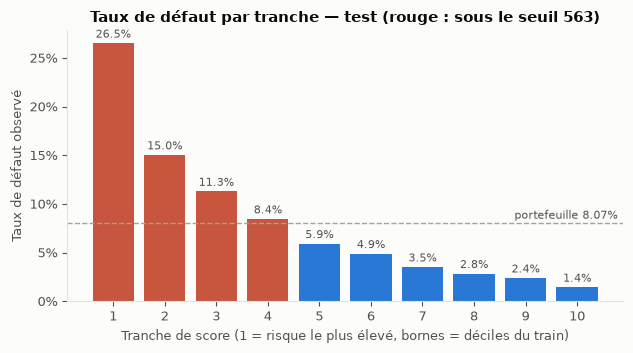

In [5]:
dt = deciles[deciles["split"].eq("test")].sort_values("decile")
cut = st["cutoffs"][reco]["cutoff"]
fig, ax = plt.subplots(figsize=(6.4, 3.6))
cols = [BLUE if lo >= cut else RED for lo in dt["score_min"]]
ax.bar(dt["decile"].astype(str), dt["default_rate"], color=cols)
for xi, v in zip(dt["decile"].astype(str), dt["default_rate"]):
    ax.text(xi, v + 0.003, f"{v:.1%}", ha="center", va="bottom", fontsize=8, color=INK2)
ax.axhline(k["default_rate"], color=GREY, ls="--", lw=1)
ax.text(0.99, k["default_rate"] + 0.004, f"portefeuille {k['default_rate']:.2%}", transform=ax.get_yaxis_transform(),
        color=INK2, fontsize=8, ha="right")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_xlabel("Tranche de score (1 = risque le plus élevé, bornes = déciles du train)")
ax.set_ylabel("Taux de défaut observé")
ax.set_title(f"Taux de défaut par tranche — test (rouge : sous le seuil {cut})")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_default_by_band.png", dpi=150)
plt.show()

### 2.3 Arbitrage des scénarios de seuil (test, LGD de base)

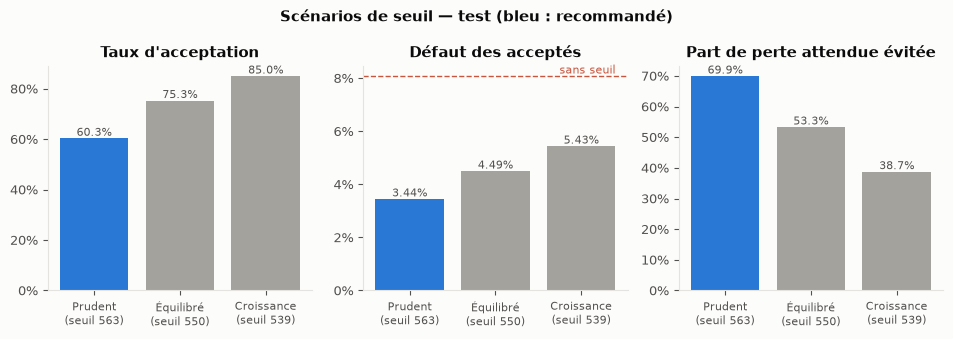

In [6]:
s = scen[scen["split"].eq("test") & np.isclose(scen["lgd"], LGD)].set_index("scenario").loc[list(st["cutoffs"])]
labels = [f"{br.SCENARIO_LABELS[i]}\n(seuil {int(s.loc[i, 'cutoff'])})" for i in s.index]
fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.4), sharey=False)
specs = (("approval_rate", "Taux d'acceptation", 1), ("bad_rate_accepted", "Défaut des acceptés", 2),
         ("el_avoided_pct", "Part de perte attendue évitée", 1))
for ax, (col, title, dec) in zip(axes, specs):
    colors = [BLUE if i == reco else GREY for i in s.index]
    ax.bar(labels, s[col], color=colors)
    for xi, v in zip(labels, s[col]):
        ax.text(xi, v, f"{v:.{dec}%}", ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
    ax.tick_params(axis="x", labelsize=8)
axes[1].axhline(k["all"]["bad_rate_accepted"], color=RED, ls="--", lw=1)
axes[1].text(2.4, k["all"]["bad_rate_accepted"], "sans seuil", color=RED, fontsize=8, ha="right", va="bottom")
fig.suptitle("Scénarios de seuil — test (bleu : recommandé)", fontweight="bold", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_scenarios.png", dpi=150)
plt.show()

### 2.4 Points de vigilance : équité par genre et dépendance aux scores externes

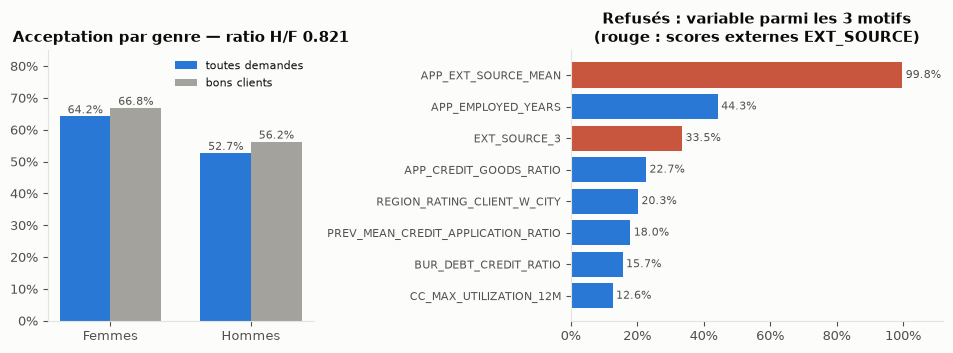

In [7]:
fair = d["fair"]
reasons = d["reasons"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.6, 3.6), gridspec_kw={"width_ratios": [1, 1.4]})
g = fair.loc[["F", "M"]]
xx = np.arange(2)
a1.bar(xx - 0.18, g["approval_rate"], 0.36, color=BLUE, label="toutes demandes")
a1.bar(xx + 0.18, g["approval_rate_goods"], 0.36, color=GREY, label="bons clients")
for xi, v in zip(np.r_[xx - 0.18, xx + 0.18], np.r_[g["approval_rate"], g["approval_rate_goods"]]):
    a1.text(xi, v + 0.01, f"{v:.1%}", ha="center", fontsize=8, color=INK2)
a1.set_xticks(xx, ["Femmes", "Hommes"])
a1.set_ylim(0, 0.85)
a1.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
a1.set_title(f"Acceptation par genre — ratio H/F {k['ratio_mf']:.3f}")
a1.legend(frameon=False, fontsize=8, loc="upper right")

top = reasons.sort_values("pct_top3_refused", ascending=True).tail(8)
colors = [RED if "EXT_SOURCE" in v else BLUE for v in top.index]
a2.barh(top.index, top["pct_top3_refused"], color=colors)
for yi, v in zip(top.index, top["pct_top3_refused"]):
    a2.text(v + 0.01, yi, f"{v:.1%}", va="center", fontsize=8, color=INK2)
a2.set_xlim(0, 1.12)
a2.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
a2.tick_params(axis="y", labelsize=8)
a2.set_title("Refusés : variable parmi les 3 motifs\n(rouge : scores externes EXT_SOURCE)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "07_vigilance.png", dpi=150)
plt.show()

## 3. Recommandation

Le texte ci-dessous est construit à partir des mêmes sorties que `docs/note_comite_credit.md`.

In [8]:
rt = k["rt"]
nxt = "equilibre"
f, pc = br._f, br.pct                       # formatage français (virgule décimale)
dlt = b["auc_diff_lgbm_minus_scorecard"]["estimate"]
txt = f"""
- **Modèle de production : la grille de score** ({k['n_vars']} variables). AUC test {f(k['auc'][('scorecard', 'test')])}, stable
  depuis le train ({f(k['auc'][('scorecard', 'train')])}), calibrée, motifs de refus lisibles. **LightGBM reste challenger** :
  +{f(dlt)} d'AUC (significatif) mais sur-appris et moins explicable.
- **Scénario {br.SCENARIO_LABELS[reco]}, seuil {rt['cutoff']}** (revue manuelle {rt['review_low']}–{rt['review_high'] - 1}) :
  acceptation {pc(rt['approval_rate'])}, défaut des acceptés {pc(rt['bad_rate_accepted'], 2)} contre {pc(k['all']['bad_rate_accepted'], 2)}
  sans seuil, {pc(rt['el_avoided_pct'])} de la perte attendue évitée, {pc(rt['good_refused_pct'])} de bons clients refusés.
  Passer au scénario {br.SCENARIO_LABELS[nxt]} n'est rentable que si la marge nette d'un bon crédit dépasse
  {pc(k['base'].loc[nxt, 'breakeven_margin'])} du montant prêté.
- **Conditions** : ratio d'acceptation H/F {f(k['ratio_mf'], 3)} à suivre (seuil {f(br.FOUR_FIFTHS, 2)}) ; zone de revue
  {pc(rt['zone_review_pct'])} des demandes ; dépendance aux scores externes (1er motif de {pc(k['ext_reason1'])} des refus) ;
  LGD supposée ; **recalibrage obligatoire sur l'historique de la banque** avant tout usage sur un portefeuille camerounais.
- **Suivi** : PSI mensuel (alerte > {f(k['psi']['thresholds']['moderate'], 2)}), défaut des acceptés, calibration par décile,
  Gini (alerte sous {f(b['scorecard_gini']['low'], 3)}), ratio H/F, volume de la zone de revue.
"""
display(Markdown(txt))
con.close()


- **Modèle de production : la grille de score** (17 variables). AUC test 0,7518, stable
  depuis le train (0,7544), calibrée, motifs de refus lisibles. **LightGBM reste challenger** :
  +0,0365 d'AUC (significatif) mais sur-appris et moins explicable.
- **Scénario Prudent, seuil 563** (revue manuelle 553–572) :
  acceptation 60,3 %, défaut des acceptés 3,44 % contre 8,07 %
  sans seuil, 69,9 % de la perte attendue évitée, 36,7 % de bons clients refusés.
  Passer au scénario Équilibré n'est rentable que si la marge nette d'un bon crédit dépasse
  4,2 % du montant prêté.
- **Conditions** : ratio d'acceptation H/F 0,821 à suivre (seuil 0,80) ; zone de revue
  25,4 % des demandes ; dépendance aux scores externes (1er motif de 99,5 % des refus) ;
  LGD supposée ; **recalibrage obligatoire sur l'historique de la banque** avant tout usage sur un portefeuille camerounais.
- **Suivi** : PSI mensuel (alerte > 0,10), défaut des acceptés, calibration par décile,
  Gini (alerte sous 0,487), ratio H/F, volume de la zone de revue.
